In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("adult.csv")

df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df = df.replace("?", "Unknown")

df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Unknown,77053,HS-grad,9,Widowed,Unknown,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Unknown,186061,Some-college,10,Widowed,Unknown,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


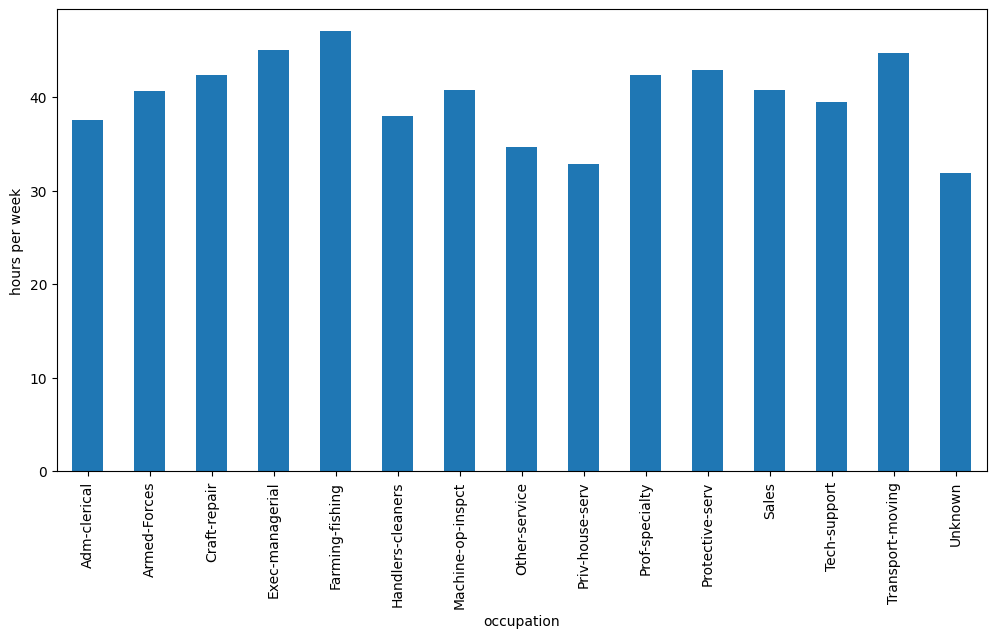

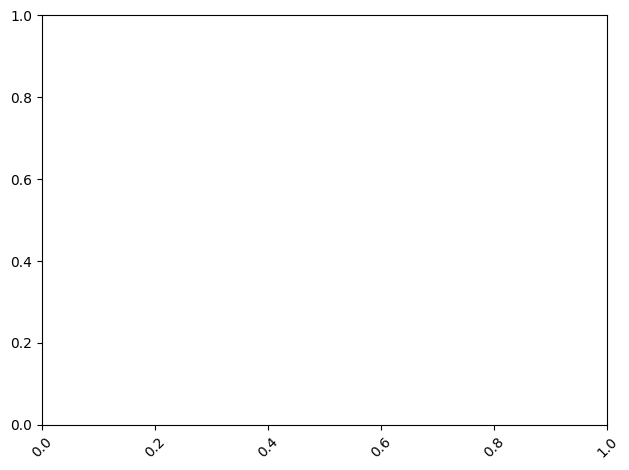

In [9]:
avg_hour = df.groupby("occupation")["hours.per.week"].mean()

plt.figure(figsize=(12,6))

avg_hour.plot(kind = "bar")

plt.xlabel("occupation")
plt.ylabel("hours per week")
plt.show()
#plt.title("bar chart")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

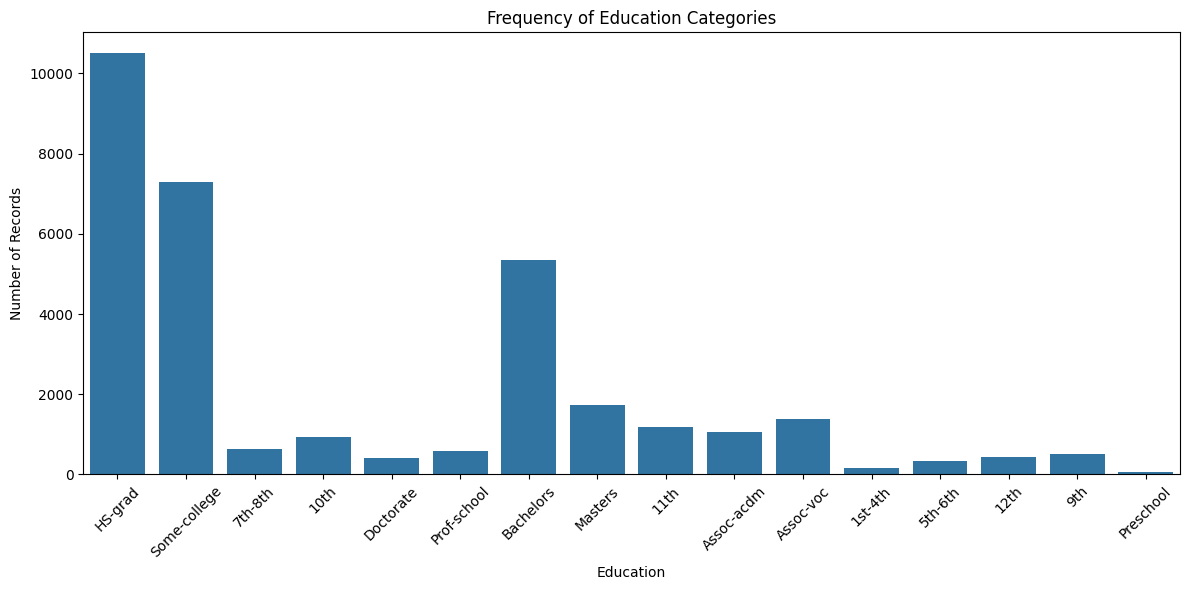

In [10]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x="education")

plt.xlabel("Education")
plt.ylabel("Number of Records")
plt.title("Frequency of Education Categories")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
most_common = df["education"].value_counts().idxmax()
most_common_count = df["education"].value_counts().max()

print("Most common education category:", most_common)
print("Number of records:", most_common_count)

Most common education category: HS-grad
Number of records: 10501


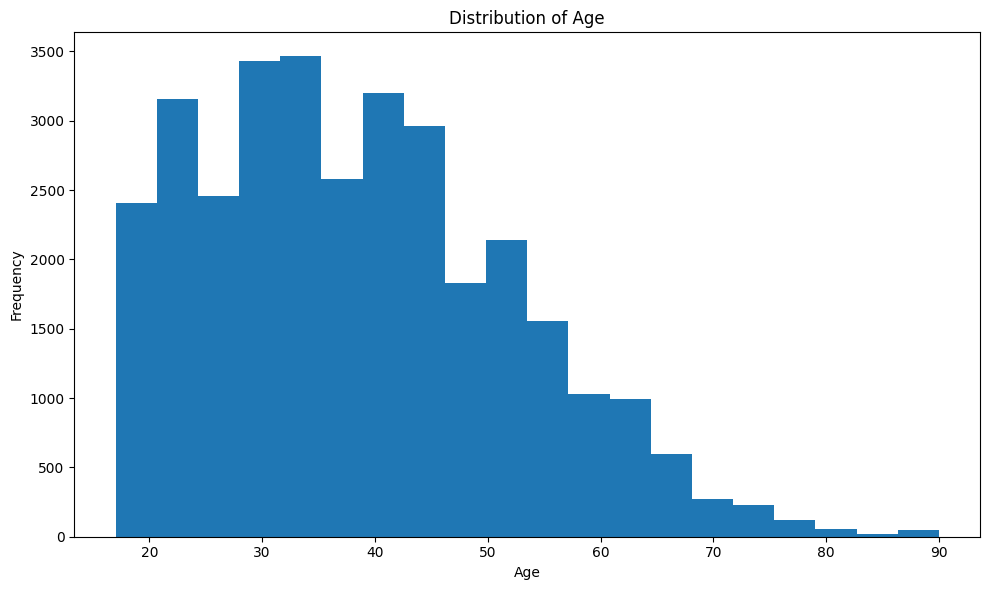

Skewness: 0.5587433694130483
The distribution is right-skewed.


In [12]:
#using age here 

plt.figure(figsize=(10, 6))

plt.hist(df["age"], bins=20)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Age")

plt.tight_layout()
plt.show()

#skewness

skewness = df["age"].skew()

print("Skewness:", skewness)

if skewness > 0:
    print("The distribution is right-skewed.")
elif skewness < 0:
    print("The distribution is left-skewed.")
else:
    print("The distribution is approximately symmetric.")

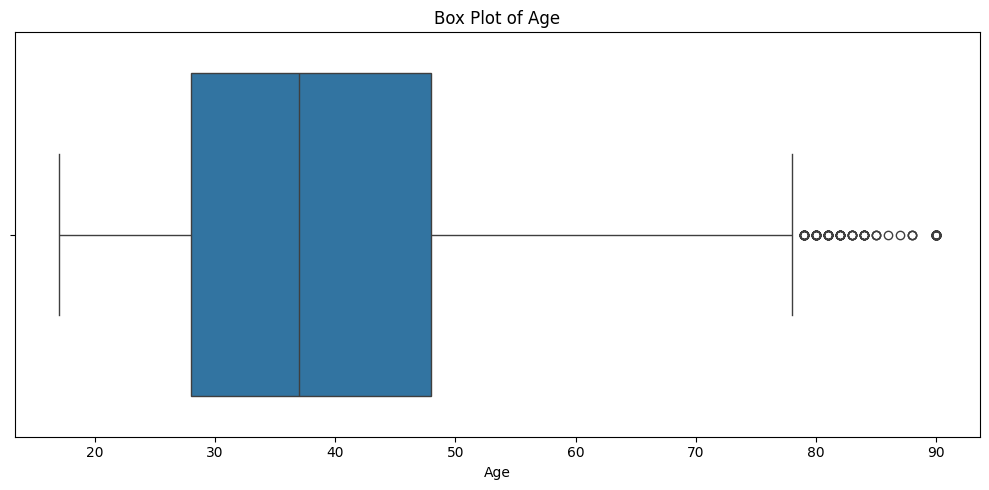

In [13]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["age"])

plt.xlabel("Age")
plt.title("Box Plot of Age")

plt.tight_layout()
plt.show()

In [16]:
# Calculate Q1 and Q3
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper bounds
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Find outliers
outliers = df[(df["age"] < lower) | (df["age"] > upper)]

# Print results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Number of IQR outliers:", len(outliers))


print("IQR outlier count:", len(outliers))
print("Compare this number with the outliers you counted visually in Task 4.")

Q1: 28.0
Q3: 48.0
IQR: 20.0
Lower Bound: -2.0
Upper Bound: 78.0
Number of IQR outliers: 143
IQR outlier count: 143
Compare this number with the outliers you counted visually in Task 4.


In [17]:
# Calculate z-score
df["zscore"] = stats.zscore(df["age"])

# Find outliers where absolute z-score > 3
outliers_z = df[df["zscore"].abs() > 3]

# Print number of outliers
print("Number of Z-score outliers:", len(outliers_z))

print("IQR outliers:", len(outliers))
print("Z-score outliers:", len(outliers_z))

if len(outliers) == len(outliers_z):
    print("Both methods flag the same number of outliers.")
else:
    print("The two methods flag different numbers of outliers.")

Number of Z-score outliers: 121
IQR outliers: 143
Z-score outliers: 121
The two methods flag different numbers of outliers.


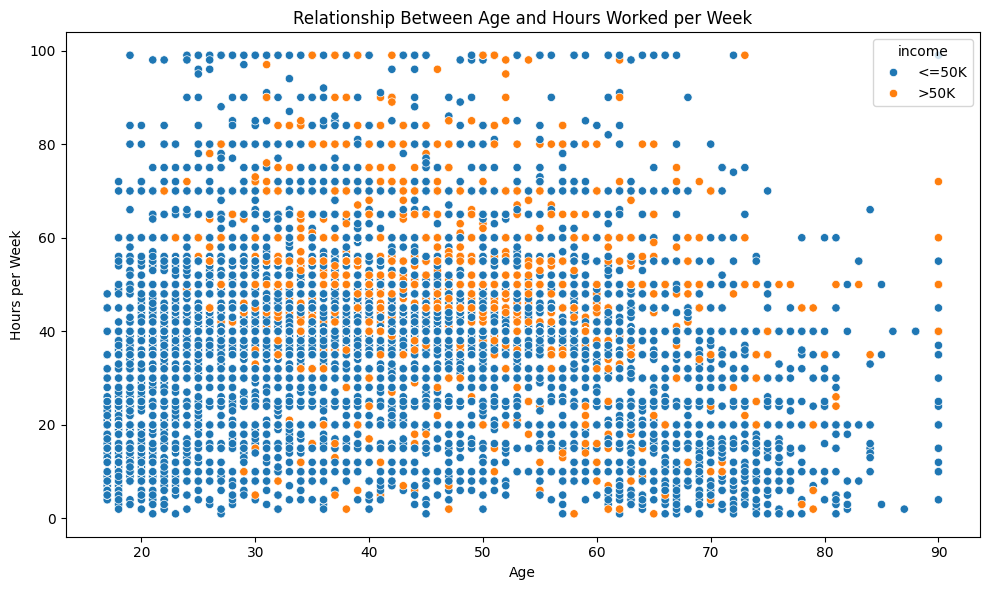

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="hours.per.week",
    hue="income"
)

plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.title("Relationship Between Age and Hours Worked per Week")

plt.tight_layout()
plt.show()

In [20]:
avg_hours_education = (
    df.groupby("education.num")["hours.per.week"]
    .mean()
    .sort_index()
)

avg_hours_education

education.num
1     36.647059
2     38.255952
3     38.897898
4     39.366873
5     38.044747
6     37.052519
7     33.925957
8     35.780600
9     40.575374
10    38.852284
11    41.610709
12    40.504217
13    42.614006
14    43.836332
15    47.425347
16    46.973366
Name: hours.per.week, dtype: float64

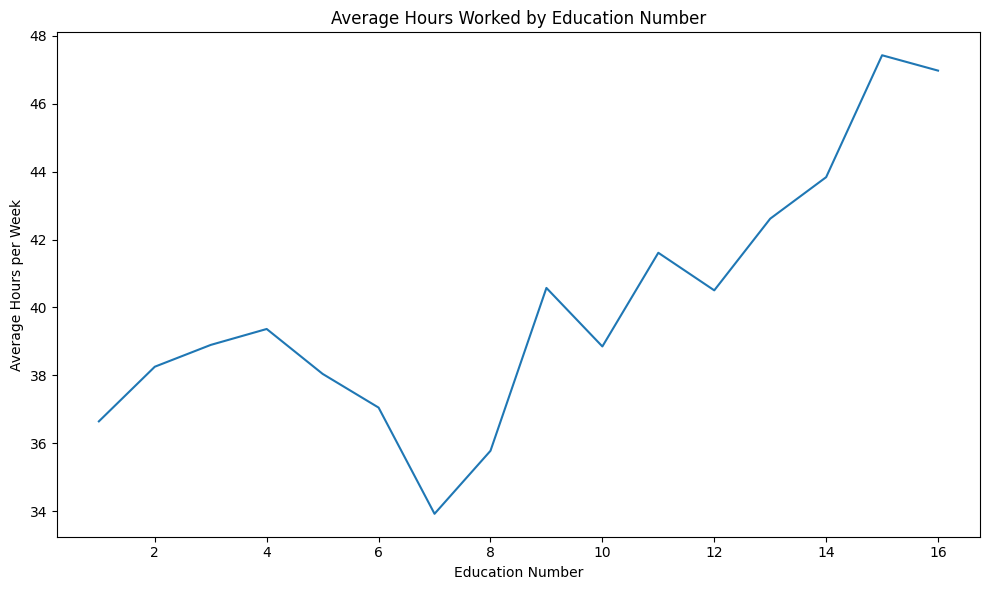

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    avg_hours_education.index,
    avg_hours_education.values
)

plt.xlabel("Education Number")
plt.ylabel("Average Hours per Week")
plt.title("Average Hours Worked by Education Number")

plt.tight_layout()
plt.show()

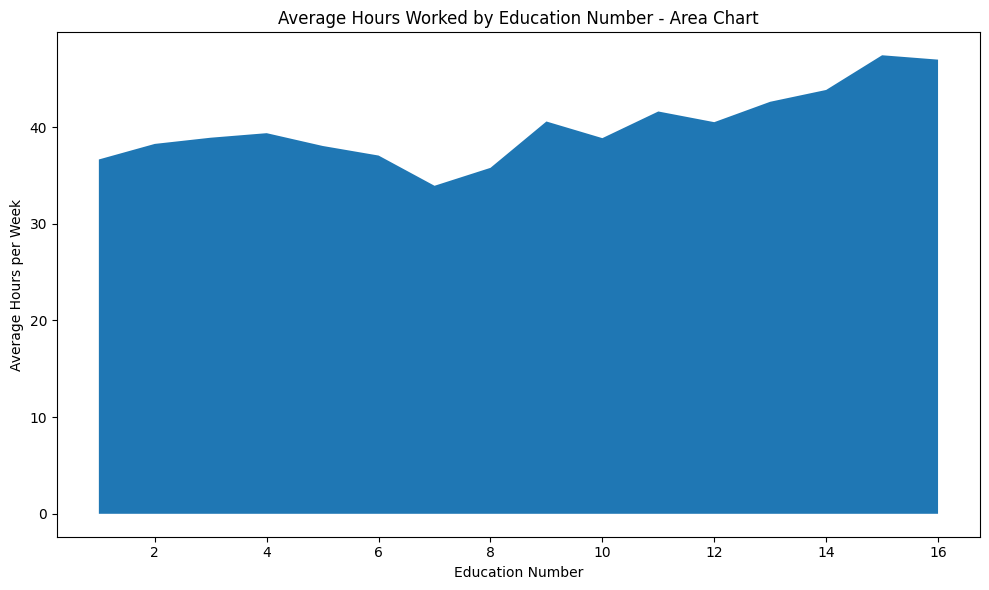

In [22]:
plt.figure(figsize=(10, 6))

plt.fill_between(
    avg_hours_education.index,
    avg_hours_education.values
)

plt.xlabel("Education Number")
plt.ylabel("Average Hours per Week")
plt.title("Average Hours Worked by Education Number - Area Chart")

plt.tight_layout()
plt.show()

The line chart makes the trend and direction of change easier to see. The area chart emphasizes the magnitude of the values because the region below the line is filled, making the changes appear visually stronger.

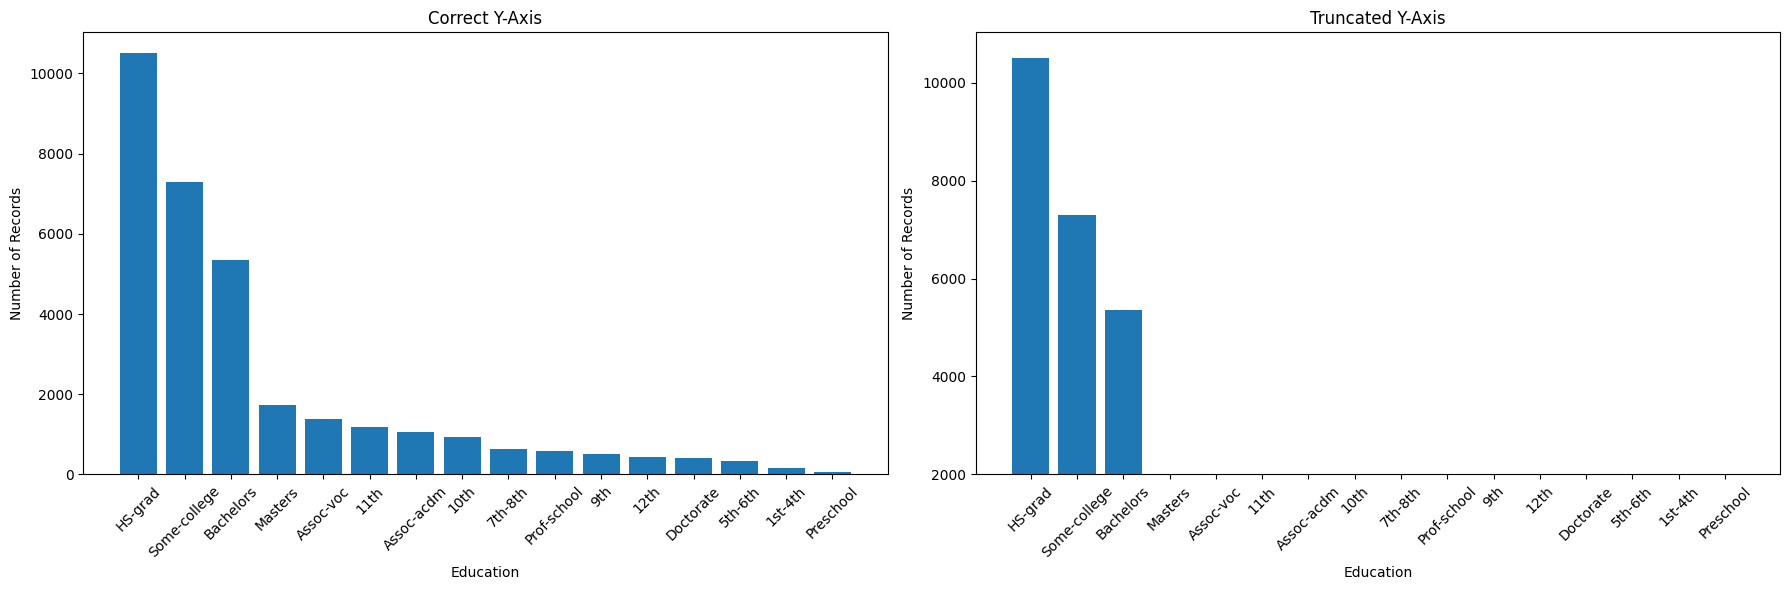

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Correct chart
axes[0].bar(
    education_counts.index,
    education_counts.values
)

axes[0].set_xlabel("Education")
axes[0].set_ylabel("Number of Records")
axes[0].set_title("Correct Y-Axis")
axes[0].set_ylim(bottom=0)
axes[0].tick_params(axis="x", rotation=45)

# Misleading chart
axes[1].bar(
    education_counts.index,
    education_counts.values
)

axes[1].set_xlabel("Education")
axes[1].set_ylabel("Number of Records")
axes[1].set_title("Truncated Y-Axis")
axes[1].set_ylim(bottom=2000)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()